In [ ]:
!pip install keras-tcn keras-tuner --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 3.2 MB/s eta 0:00:00


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from keras.models import Model
from keras.layers import Input, Dense, Dropout, MultiHeadAttention, LayerNormalization, GlobalAveragePooling1D, GRU
from keras.callbacks import EarlyStopping
import tensorflow as tf

In [2]:
data = pd.read_csv("bismillah data.csv")
data

,country,date,sector,GWh
0,Mexico,1/1/2022,Gas,493.556
1,Mexico,2/1/2022,Gas,493.653
2,Mexico,3/1/2022,Gas,494.662
3,Mexico,4/1/2022,Gas,498.657
4,Mexico,5/1/2022,Gas,499.937
...,...,...,...,...
1210,Mexico,26/04/2025,Gas,649.285
1211,Mexico,27/04/2025,Gas,651.161
1212,Mexico,28/04/2025,Gas,650.995
1213,Mexico,29/04/2025,Gas,654.125


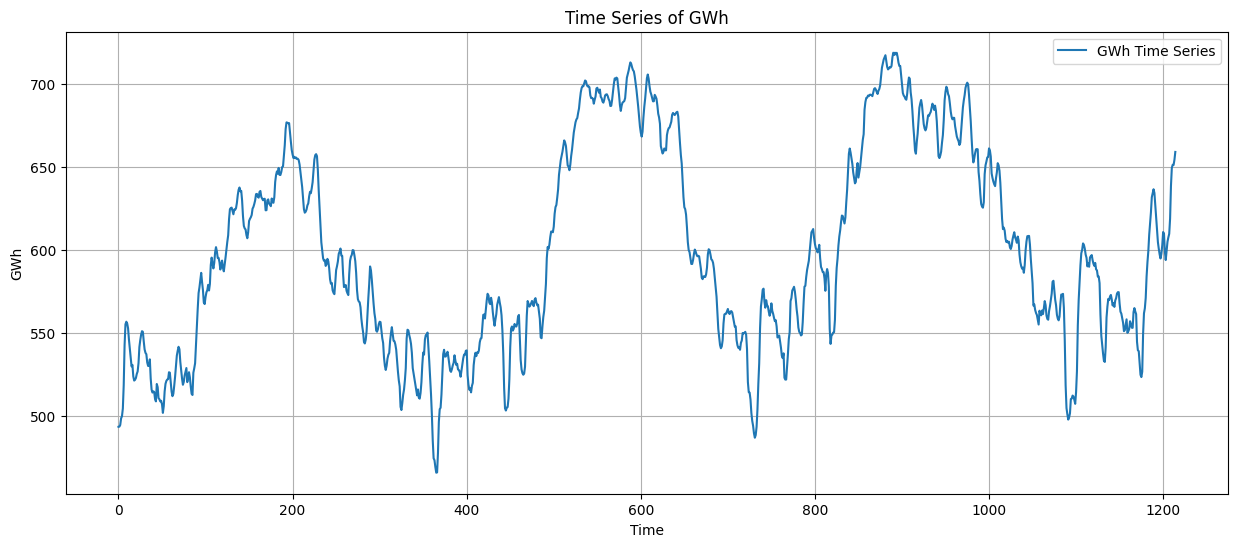

In [ ]:
# Plot Time Series GWh
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 6))
plt.plot(data["GWh"], label='GWh Time Series')
plt.xlabel('Time')
plt.ylabel('GWh')
plt.title('Time Series of GWh')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# Data Preprocessing
df = data[["GWh"]].values
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)

In [4]:
lookback_window = 30

In [5]:
x = []
y = []
for i in tqdm(range(lookback_window, len(df_scaled))):
    x.append(df_scaled[i - lookback_window:i])
    y.append(df_scaled[i])

x = np.array(x)
y = np.array(y)
x = np.reshape(x, (x.shape[0], x.shape[1], 1))

100%|██████████| 1185/1185 [00:00<00:00, 294935.33it/s]


In [6]:
train_size = int(len(x) * 0.8)
x_train, x_val = x[:train_size], x[train_size:]
y_train, y_val = y[:train_size], y[train_size:]

In [ ]:
def build_model_gru_attention(hp):
    input_layer = Input(shape=(lookback_window, 1))

    # GRU Layer
    gru_output = tf.keras.layers.GRU(
        units=hp.Choice('gru_units', [8, 16, 32]),
        return_sequences=True  # WAJIB untuk attention
    )(input_layer)

    attention_output = MultiHeadAttention(
        num_heads=hp.Choice('num_heads', [2, 4]),
        key_dim=hp.Choice('key_dim', [8, 16])
    )(gru_output, gru_output)

    x = LayerNormalization()(attention_output)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(hp.Float('final_dropout', 0.1, 0.5, step=0.1))(x)

    output_layer = Dense(1, activation='linear')(x)

    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [ ]:
import shutil

# Hapus folder hasil tuning sebelumnya
shutil.rmtree('attention_gru_tuning/attention_gru_forecast', ignore_errors=True)

In [ ]:
from keras_tuner.tuners import RandomSearch

tuner = RandomSearch(
    build_model_gru_attention,
    objective='val_loss',
    max_trials=5,
    executions_per_trial=1,
    directory='attention_gru_tuning',
    project_name='attention_gru_forecast'
)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

tuner.search(x_train, y_train,
             validation_data=(x_val, y_val),
             epochs=100,
             batch_size=32,
             callbacks=[early_stop],
             verbose=1)

Trial 5 Complete [00h 00m 34s]
val_loss: 0.011893317103385925

Best val_loss So Far: 0.004441470839083195
Total elapsed time: 00h 07m 07s


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]  # Mendapatkan model terbaik
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]  # Mendapatkan hyperparameter terbaik

print("Best Hyperparameters (GRU + Attention):")
print("GRU Units      :", best_hp.get('gru_units'))
print("Num Heads      :", best_hp.get('num_heads'))
print("Key Dimension  :", best_hp.get('key_dim'))
print("Final Dropout  :", best_hp.get('final_dropout'))

Best Hyperparameters (GRU + Attention):
GRU Units      : 32
Num Heads      : 4
Key Dimension  : 16
Final Dropout  : 0.4


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Training model
history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.0210 - mae: 0.1133 - val_loss: 0.0051 - val_mae: 0.0536
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0068 - mae: 0.0650 - val_loss: 0.0052 - val_mae: 0.0540
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0073 - mae: 0.0687 - val_loss: 0.0050 - val_mae: 0.0564
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0073 - mae: 0.0680 - val_loss: 0.0049 - val_mae: 0.0530
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0063 - mae: 0.0625 - val_loss: 0.0046 - val_mae: 0.0514
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0054 - mae: 0.0590 - val_loss: 0.0053 - val_mae: 0.0555
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0062 - mae: 0.0618 - val_loss: 0.0043 - val_mae: 0.0505
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0059 - mae: 0.0607 - val_loss: 0.0041 - val_mae: 0.0501
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - lo

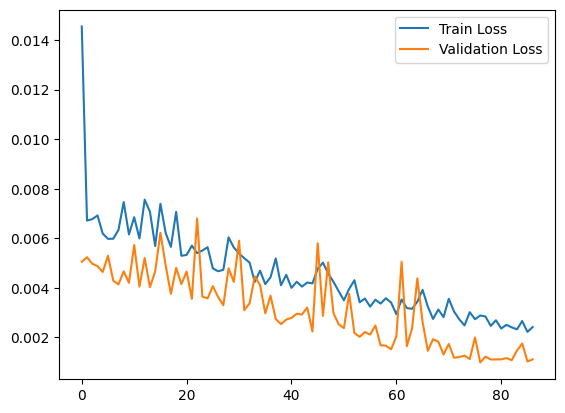

In [ ]:
# Plot Learning Curve
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

In [ ]:
# Prediksi dan Inverse Scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step


In [ ]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk Evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi Performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.0667%
MAE on Testing Data: 6.1992
RMSE on Testing Data: 7.9328
R2 Score on Testing Data: 0.9601


In [ ]:
# Evaluasi pada training data
predict_train = best_model.predict(x_train)
predict_train_original_scale = scaler.inverse_transform(predict_train)
y_train_original_scale = scaler.inverse_transform(y_train)

# Flatten untuk evaluasi training
y_train_flat = y_train_original_scale.reshape(-1)
predict_train_flat = predict_train_original_scale.reshape(-1)

# Evaluasi performa pada training data
mape_train = mean_absolute_percentage_error(y_train_flat, predict_train_flat) * 100
mae = np.mean(np.abs(predict_train_flat - y_train_flat))
rmse = sqrt(mean_squared_error(y_train_flat, predict_train_flat))
r2_train = r2_score(y_train_flat, predict_train_flat)

print(f'MAPE on Training Data: {mape_train:.4f}%')
print(f'MAE on Training Data: {mae:.4f}')
print(f'RMSE on Training Data: {rmse:.4f}')
print(f'R2 Score on Training Data: {r2_train:.4f}')

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
MAPE on Training Data: 1.0215%
MAE on Training Data: 6.1680
RMSE on Training Data: 7.6910
R2 Score on Training Data: 0.9856


In [ ]:
best_model.save('best_attention_gru_model.keras')

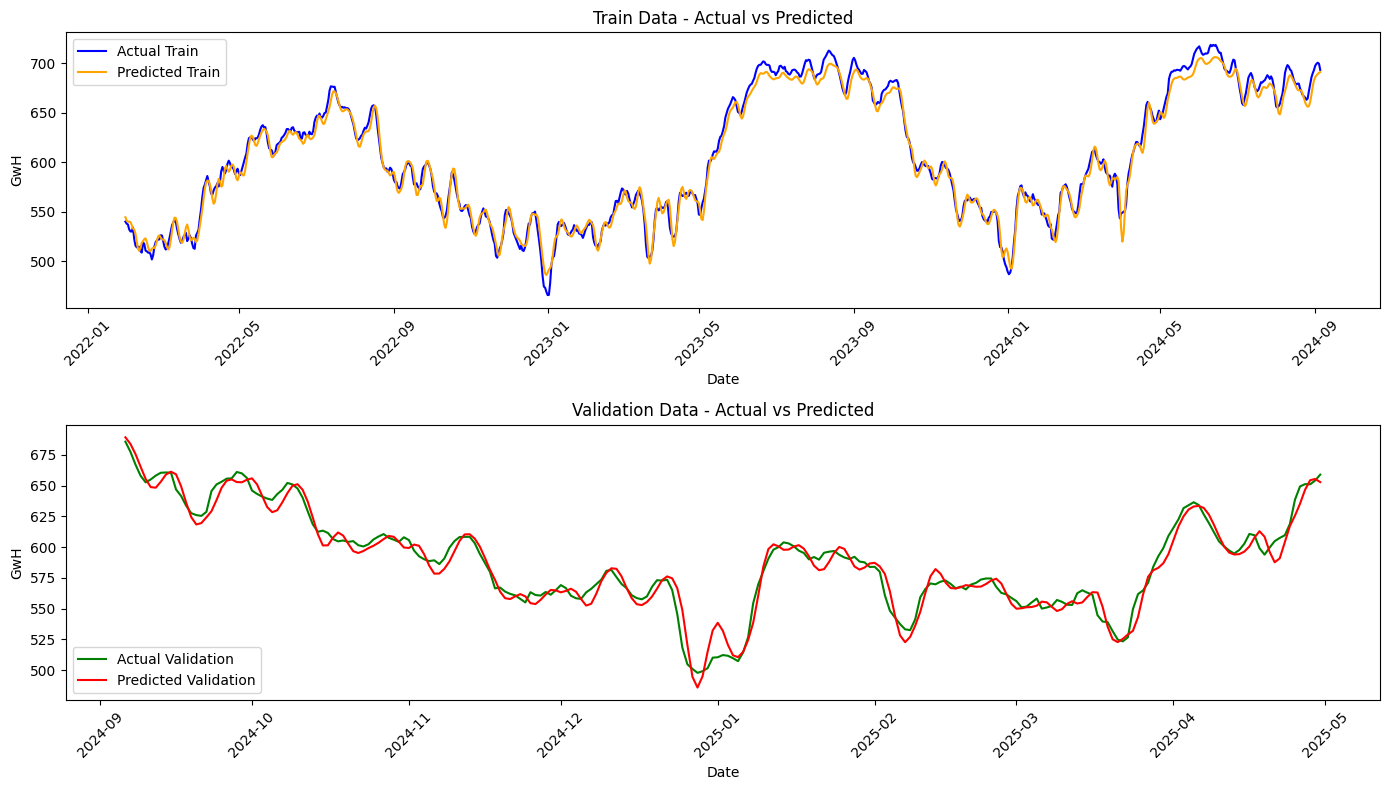

In [ ]:
date_train = data['date'].iloc[lookback_window:train_size + lookback_window]
date_val = data['date'].iloc[train_size + lookback_window:]

# Pastikan panjang data tanggal sesuai dengan data plot
date_train = date_train[:len(y_train_original_scale)]
date_val = date_val[:len(y_val_original_scale)]

# Konversi tanggal ke datetime objects
date_train = pd.to_datetime(date_train, format='%d/%m/%Y')
date_val = pd.to_datetime(date_val, format='%d/%m/%Y')

plt.figure(figsize=(14, 8))

# Plot data training
plt.subplot(2, 1, 1)
plt.plot(date_train, y_train_original_scale, label='Actual Train', color='blue')
plt.plot(date_train, predict_train_original_scale, label='Predicted Train', color='orange')
plt.title('Train Data - Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)

# Plot data validasi
plt.subplot(2, 1, 2)
plt.plot(date_val, y_val_original_scale, label='Actual Validation', color='green')
plt.plot(date_val, predict_original_scale, label='Predicted Validation', color='red')
plt.title('Validation Data - Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━

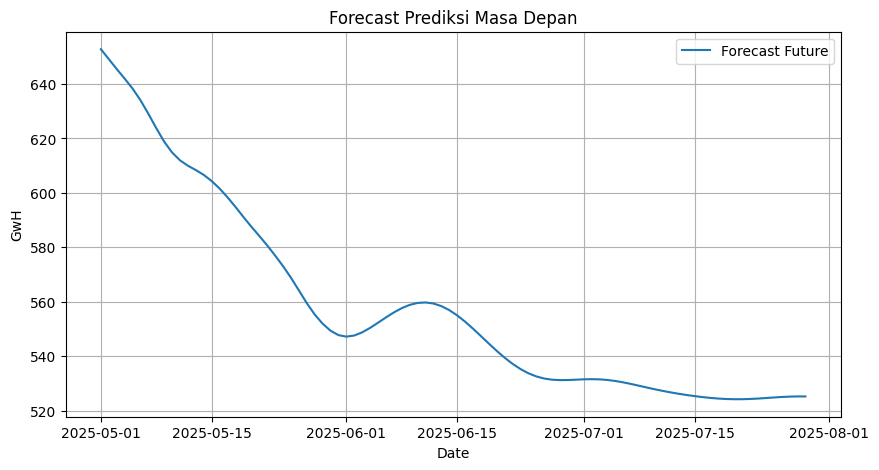

In [ ]:
n_forecast = 90  # jumlah hari ke depan
forecast_input = x_val[-1]
forecast_input = forecast_input.reshape(1, forecast_input.shape[0], 1)

future_forecast_scaled = []

for _ in range(n_forecast):
    pred = best_model.predict(forecast_input)
    future_forecast_scaled.append(pred[0, 0])

    # Perbarui input window: geser dan tambahkan prediksi terbaru
    new_input = np.append(forecast_input[0, 1:], [[pred[0, 0]]], axis=0)
    forecast_input = new_input.reshape(1, new_input.shape[0], 1)

# Inverse transform hasil prediksi
future_forecast_scaled = np.array(future_forecast_scaled).reshape(-1, 1)
future_forecast = scaler.inverse_transform(future_forecast_scaled)

# Generate future dates based on the last date in the original data
last_date = pd.to_datetime(data['date'], dayfirst=True).iloc[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_forecast, freq='D')

# Plot prediksi masa depan
plt.figure(figsize=(10,5))
plt.plot(future_dates, future_forecast, label="Forecast Future")
plt.title("Forecast Prediksi Masa Depan")
plt.xlabel("Date")
plt.ylabel("GwH")
plt.grid(True)
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━

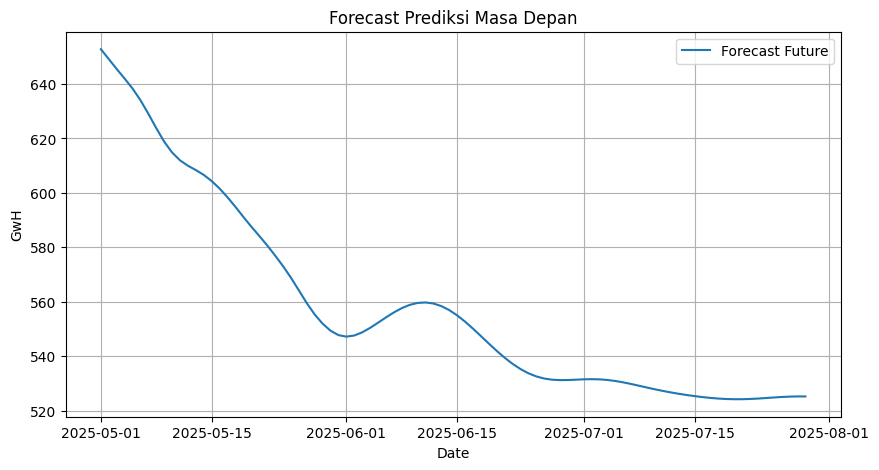

In [ ]:
n_forecast = 90  # jumlah hari ke depan
forecast_input = x_val[-1]
forecast_input = forecast_input.reshape(1, forecast_input.shape[0], 1)

future_forecast_scaled = []

for _ in range(n_forecast):
    pred = best_model.predict(forecast_input)
    future_forecast_scaled.append(pred[0, 0])

    # Perbarui input window: geser dan tambahkan prediksi terbaru
    new_input = np.append(forecast_input[0, 1:], [[pred[0, 0]]], axis=0)
    forecast_input = new_input.reshape(1, new_input.shape[0], 1)

# Inverse transform hasil prediksi
future_forecast_scaled = np.array(future_forecast_scaled).reshape(-1, 1)
future_forecast = scaler.inverse_transform(future_forecast_scaled)

# Generate future dates based on the last date in the original data
last_date = pd.to_datetime(data['date'], dayfirst=True).iloc[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_forecast, freq='D')

# Plot prediksi masa depan
plt.figure(figsize=(10,5))
plt.plot(future_dates, future_forecast, label="Forecast Future")
plt.title("Forecast Prediksi Masa Depan")
plt.xlabel("Date")
plt.ylabel("GwH")
plt.grid(True)
plt.legend()
plt.show()

Could not infer frequency, defaulting to daily. Error: 'DatetimeIndexResampler' object has no attribute 'index'


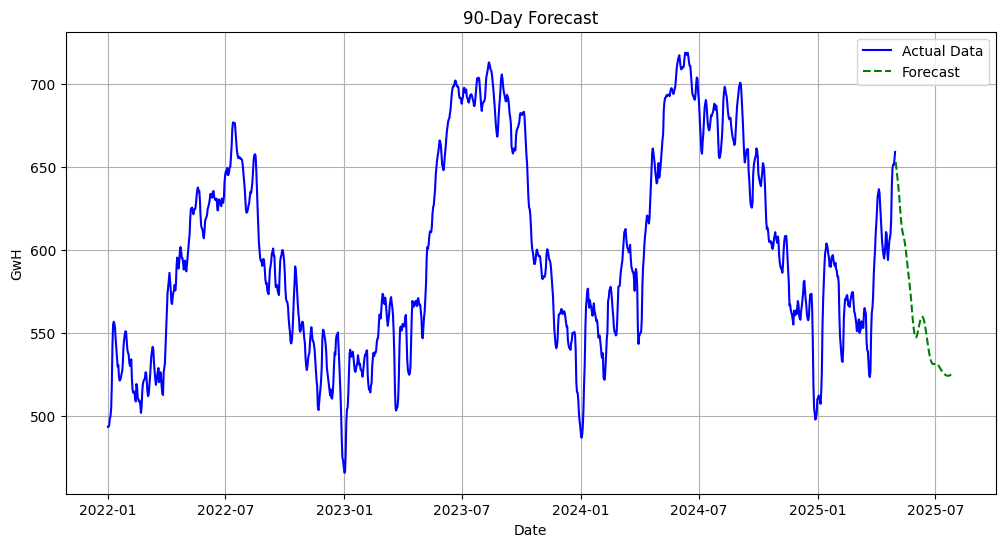

In [ ]:
data['date'] = pd.to_datetime(data['date'], dayfirst=True)
plt.figure(figsize=(12, 6))
actual_dates = data['date'][:len(df)]
plt.plot(actual_dates, df, label='Actual Data', color='blue')

last_actual_date = data['date'].iloc[len(df)-1]
try:
    freq = pd.infer_freq(data['date'])
    if freq is None:
        temp_series = pd.Series(index=data['date'])
        resampled_index = temp_series.resample('D').index
        freq = resampled_index.freq
        if freq is None:
             freq = 'D'
    future_dates = pd.date_range(start=last_actual_date, periods=n_forecast + 1, freq=freq)[1:]

except Exception as e:
    print(f"Could not infer frequency, defaulting to daily. Error: {e}")
    future_dates = pd.date_range(start=last_actual_date, periods=n_forecast + 1, freq='D')[1:]


plt.plot(future_dates, future_forecast, label='Forecast', color='green', linestyle='--')

plt.title('90-Day Forecast')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.grid(True)
plt.show()

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


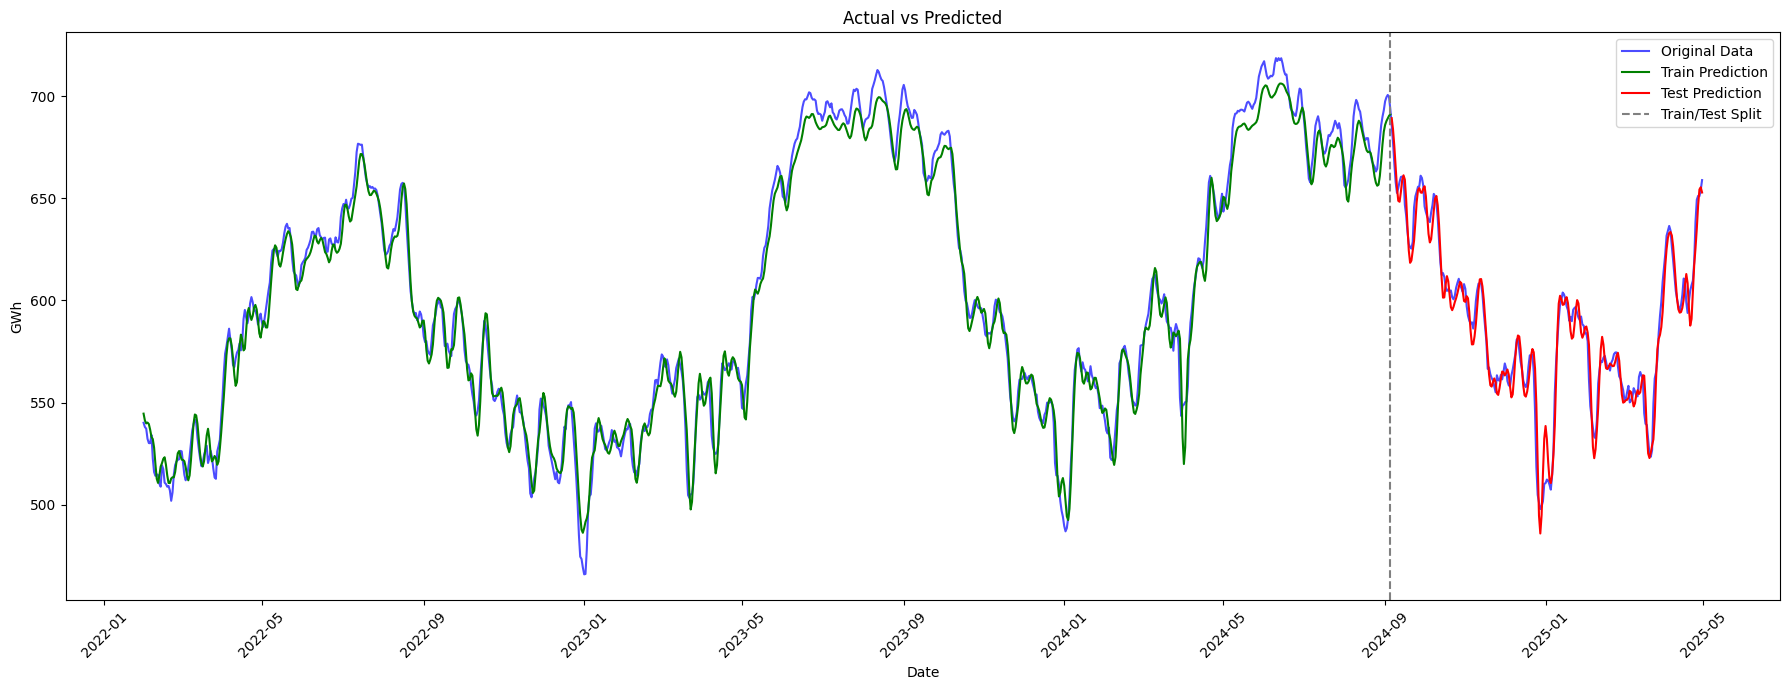

In [ ]:
full_data_original_scale = scaler.inverse_transform(df_scaled).flatten()

# Calculate predictions for the entire dataset
full_predict = best_model.predict(x)
full_predict_original_scale = scaler.inverse_transform(full_predict).flatten()

split_index = train_size

# Use full_dates for the x-axis of the original data plot
original_dates = pd.to_datetime(data['date'].iloc[lookback_window:], dayfirst=True)

train_dates = original_dates[:split_index]
test_dates = original_dates[split_index:]


plt.figure(figsize=(18, 7))
# Slice full_data_original_scale to match the length of original_dates
plt.plot(original_dates, full_data_original_scale[lookback_window:], label='Original Data', color='blue', alpha=0.7)
plt.plot(train_dates, full_predict_original_scale[:split_index], label='Train Prediction', color='green')
plt.plot(test_dates, full_predict_original_scale[split_index:], label='Test Prediction', color='red')

split_date = train_dates.iloc[-1] # Use the last date of the training set as split point
plt.axvline(split_date, color='gray', linestyle='--', label='Train/Test Split')

plt.title('Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GWh')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)
plt.tight_layout()
plt.show()

In [7]:
# cek mode akhir
from tensorflow.keras.models import load_model

best_model = load_model("/content/best_attention_gru_model.keras")

In [8]:
# Prediksi dan Inverse Scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


In [9]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk Evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi Performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.0667%
MAE on Testing Data: 6.1992
RMSE on Testing Data: 7.9328
R2 Score on Testing Data: 0.9601
